# UCS420 – Cognitive Computing
## Lab Assignment 8: NLP using Python – II
**Feature extraction from text, sentiment analysis and text generation**


Aadish Jain

Roll No: 1024170413

Batch: 3Q33

### 0. Setup – install libraries and download NLTK data

In [32]:
# !pip install -q nltk textblob vaderSentiment wordcloud scikit-learn pandas matplotlib tensorflow

import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4", "vader_lexicon"]:
    nltk.download(pkg, quiet=True)
print("NLTK data ready")

NLTK data ready


---
# Q1. Text pre-processing basics
**Topic chosen:** Cricket  (5–6 sentence paragraph)

In [2]:
text = ("Cricket is more than just a sport in India; it is a festival that brings millions of people together. "
        "I have loved the game since I was a child, when I used to play with my friends in the narrow lanes behind our house. "
        "Watching a batter chase a target in the final overs of a tense match is an experience that no other sport can match! "
        "The unpredictable nature of the game, where a single wicket can change everything, keeps me glued to the screen. "
        "Today, T20 leagues like the IPL have made cricket faster, louder and more exciting than ever before. "
        "Playing and watching cricket has taught me patience, teamwork and the importance of never giving up.")

print(text)

Cricket is more than just a sport in India; it is a festival that brings millions of people together. I have loved the game since I was a child, when I used to play with my friends in the narrow lanes behind our house. Watching a batter chase a target in the final overs of a tense match is an experience that no other sport can match! The unpredictable nature of the game, where a single wicket can change everything, keeps me glued to the screen. Today, T20 leagues like the IPL have made cricket faster, louder and more exciting than ever before. Playing and watching cricket has taught me patience, teamwork and the importance of never giving up.


### Q1.1 Convert to lowercase and remove punctuation using `re`

In [3]:
import re

lower_text = text.lower()
clean_text = re.sub(r"[^\w\s]", "", lower_text)      # keep only word characters and whitespace
clean_text = re.sub(r"\s+", " ", clean_text).strip() # tidy up extra spaces

print("Lowercase text:\n", lower_text, "\n")
print("Cleaned text (no punctuation):\n", clean_text)

Lowercase text:
 cricket is more than just a sport in india; it is a festival that brings millions of people together. i have loved the game since i was a child, when i used to play with my friends in the narrow lanes behind our house. watching a batter chase a target in the final overs of a tense match is an experience that no other sport can match! the unpredictable nature of the game, where a single wicket can change everything, keeps me glued to the screen. today, t20 leagues like the ipl have made cricket faster, louder and more exciting than ever before. playing and watching cricket has taught me patience, teamwork and the importance of never giving up. 

Cleaned text (no punctuation):
 cricket is more than just a sport in india it is a festival that brings millions of people together i have loved the game since i was a child when i used to play with my friends in the narrow lanes behind our house watching a batter chase a target in the final overs of a tense match is an experien

### Q1.2 Tokenize into sentences and words

In [4]:
from nltk.tokenize import sent_tokenize, word_tokenize

# Sentences are tokenized from the ORIGINAL text (punctuation is needed to find sentence boundaries)
sentences = sent_tokenize(text)
print("Number of sentences:", len(sentences))
for i, s in enumerate(sentences, 1):
    print(f"  {i}. {s}")

# Words are tokenized from the CLEANED text
words = word_tokenize(clean_text)
print("\nNumber of words:", len(words))
print(words)

Number of sentences: 6
  1. Cricket is more than just a sport in India; it is a festival that brings millions of people together.
  2. I have loved the game since I was a child, when I used to play with my friends in the narrow lanes behind our house.
  3. Watching a batter chase a target in the final overs of a tense match is an experience that no other sport can match!
  4. The unpredictable nature of the game, where a single wicket can change everything, keeps me glued to the screen.
  5. Today, T20 leagues like the IPL have made cricket faster, louder and more exciting than ever before.
  6. Playing and watching cricket has taught me patience, teamwork and the importance of never giving up.

Number of words: 119
['cricket', 'is', 'more', 'than', 'just', 'a', 'sport', 'in', 'india', 'it', 'is', 'a', 'festival', 'that', 'brings', 'millions', 'of', 'people', 'together', 'i', 'have', 'loved', 'the', 'game', 'since', 'i', 'was', 'a', 'child', 'when', 'i', 'used', 'to', 'play', 'with', '

### Q1.3 `split()` vs NLTK `word_tokenize()`

In [5]:
split_tokens = text.split()          # on the original text (with punctuation)
nltk_tokens  = word_tokenize(text)

print("split()         ->", len(split_tokens), "tokens")
print("word_tokenize() ->", len(nltk_tokens), "tokens\n")
print("First 15 with split()         :", split_tokens[:15])
print("First 15 with word_tokenize() :", nltk_tokens[:15])

print("\nTokens produced ONLY by split() (punctuation stuck to the word):")
print([t for t in split_tokens if t not in nltk_tokens])

print("\nTokens produced ONLY by word_tokenize() (punctuation separated):")
print(sorted(set(t for t in nltk_tokens if t not in split_tokens)))

# A small extra example with contractions
demo = "I don't think it's over, isn't it? Let's wait!"
print("\nDemo sentence:", demo)
print("split()         :", demo.split())
print("word_tokenize() :", word_tokenize(demo))

split()         -> 119 tokens
word_tokenize() -> 132 tokens

First 15 with split()         : ['Cricket', 'is', 'more', 'than', 'just', 'a', 'sport', 'in', 'India;', 'it', 'is', 'a', 'festival', 'that', 'brings']
First 15 with word_tokenize() : ['Cricket', 'is', 'more', 'than', 'just', 'a', 'sport', 'in', 'India', ';', 'it', 'is', 'a', 'festival', 'that']

Tokens produced ONLY by split() (punctuation stuck to the word):
['India;', 'together.', 'child,', 'house.', 'match!', 'game,', 'everything,', 'screen.', 'Today,', 'faster,', 'before.', 'patience,', 'up.']

Tokens produced ONLY by word_tokenize() (punctuation separated):
['!', ',', '.', ';', 'India', 'Today', 'before', 'child', 'everything', 'faster', 'house', 'patience', 'screen', 'together', 'up']

Demo sentence: I don't think it's over, isn't it? Let's wait!
split()         : ['I', "don't", 'think', "it's", 'over,', "isn't", 'it?', "Let's", 'wait!']
word_tokenize() : ['I', 'do', "n't", 'think', 'it', "'s", 'over', ',', 'is', "n't",

**Observation – `split()` vs `word_tokenize()`**

| Point | `str.split()` | `nltk.word_tokenize()` |
|---|---|---|
| Splits on | only whitespace | whitespace **and** linguistic rules (punctuation, contractions) |
| Punctuation | stays glued to the word (`together.`, `India;`, `match!`) | separated into its own token (`together`, `.`) |
| Contractions | `don't` stays as one token | split into `do` + `n't` |
| Token count | usually fewer | usually more (punctuation marks become tokens) |
| Speed / dependency | very fast, no library | slower, needs NLTK + `punkt` data |
| Best for | quick-and-dirty splitting of already-clean text | real NLP pipelines on raw text |

So `split()` treats `"together."` and `"together"` as **different** words, which hurts counting and feature extraction. `word_tokenize()` avoids this problem.

### Q1.4 Remove stopwords (NLTK list)

In [6]:
from nltk.corpus import stopwords

stop_words = set(stopwords.words("english"))
print("Total English stopwords in NLTK:", len(stop_words))

filtered_words = [w for w in words if w not in stop_words]

print("\nBefore stopword removal:", len(words), "words")
print("After stopword removal :", len(filtered_words), "words\n")
print(filtered_words)

Total English stopwords in NLTK: 198

Before stopword removal: 119 words
After stopword removal : 60 words

['cricket', 'sport', 'india', 'festival', 'brings', 'millions', 'people', 'together', 'loved', 'game', 'since', 'child', 'used', 'play', 'friends', 'narrow', 'lanes', 'behind', 'house', 'watching', 'batter', 'chase', 'target', 'final', 'overs', 'tense', 'match', 'experience', 'sport', 'match', 'unpredictable', 'nature', 'game', 'single', 'wicket', 'change', 'everything', 'keeps', 'glued', 'screen', 'today', 't20', 'leagues', 'like', 'ipl', 'made', 'cricket', 'faster', 'louder', 'exciting', 'ever', 'playing', 'watching', 'cricket', 'taught', 'patience', 'teamwork', 'importance', 'never', 'giving']


### Q1.5 Word-frequency distribution (excluding stopwords)

Top 10 most frequent words:
  cricket      3
  sport        2
  game         2
  watching     2
  match        2
  india        1
  festival     1
  brings       1
  millions     1
  people       1


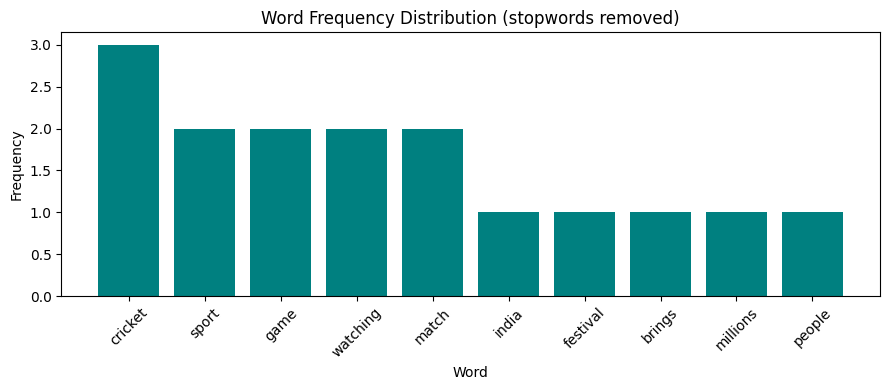

In [7]:
from nltk import FreqDist
import matplotlib.pyplot as plt

fdist = FreqDist(filtered_words)
print("Top 10 most frequent words:")
for word, freq in fdist.most_common(10):
    print(f"  {word:<12} {freq}")

top = fdist.most_common(10)
plt.figure(figsize=(9, 4))
plt.bar([w for w, _ in top], [f for _, f in top], color="teal")
plt.title("Word Frequency Distribution (stopwords removed)")
plt.xlabel("Word"); plt.ylabel("Frequency")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

---
# Q2. Regex features, stemming and lemmatization (same paragraph as Q1)

### Q2.1 Extract alphabet-only words with `re.findall()`

In [8]:
alpha_words = re.findall(r"\b[a-zA-Z]+\b", text.lower())
print("Alphabetic words extracted:", len(alpha_words))
print(alpha_words)
# Note: tokens such as 't20' (letters + digits) are dropped because they are not purely alphabetic.

Alphabetic words extracted: 118
['cricket', 'is', 'more', 'than', 'just', 'a', 'sport', 'in', 'india', 'it', 'is', 'a', 'festival', 'that', 'brings', 'millions', 'of', 'people', 'together', 'i', 'have', 'loved', 'the', 'game', 'since', 'i', 'was', 'a', 'child', 'when', 'i', 'used', 'to', 'play', 'with', 'my', 'friends', 'in', 'the', 'narrow', 'lanes', 'behind', 'our', 'house', 'watching', 'a', 'batter', 'chase', 'a', 'target', 'in', 'the', 'final', 'overs', 'of', 'a', 'tense', 'match', 'is', 'an', 'experience', 'that', 'no', 'other', 'sport', 'can', 'match', 'the', 'unpredictable', 'nature', 'of', 'the', 'game', 'where', 'a', 'single', 'wicket', 'can', 'change', 'everything', 'keeps', 'me', 'glued', 'to', 'the', 'screen', 'today', 'leagues', 'like', 'the', 'ipl', 'have', 'made', 'cricket', 'faster', 'louder', 'and', 'more', 'exciting', 'than', 'ever', 'before', 'playing', 'and', 'watching', 'cricket', 'has', 'taught', 'me', 'patience', 'teamwork', 'and', 'the', 'importance', 'of', 'nev

### Q2.2 Remove stopwords

In [9]:
alpha_filtered = [w for w in alpha_words if w not in stop_words]
print("After stopword removal:", len(alpha_filtered), "words")
print(alpha_filtered)

After stopword removal: 59 words
['cricket', 'sport', 'india', 'festival', 'brings', 'millions', 'people', 'together', 'loved', 'game', 'since', 'child', 'used', 'play', 'friends', 'narrow', 'lanes', 'behind', 'house', 'watching', 'batter', 'chase', 'target', 'final', 'overs', 'tense', 'match', 'experience', 'sport', 'match', 'unpredictable', 'nature', 'game', 'single', 'wicket', 'change', 'everything', 'keeps', 'glued', 'screen', 'today', 'leagues', 'like', 'ipl', 'made', 'cricket', 'faster', 'louder', 'exciting', 'ever', 'playing', 'watching', 'cricket', 'taught', 'patience', 'teamwork', 'importance', 'never', 'giving']


### Q2.3 Stemming with `PorterStemmer`

In [10]:
from nltk.stem import PorterStemmer

stemmer = PorterStemmer()
stemmed = [stemmer.stem(w) for w in alpha_filtered]
print(stemmed)

['cricket', 'sport', 'india', 'festiv', 'bring', 'million', 'peopl', 'togeth', 'love', 'game', 'sinc', 'child', 'use', 'play', 'friend', 'narrow', 'lane', 'behind', 'hous', 'watch', 'batter', 'chase', 'target', 'final', 'over', 'tens', 'match', 'experi', 'sport', 'match', 'unpredict', 'natur', 'game', 'singl', 'wicket', 'chang', 'everyth', 'keep', 'glu', 'screen', 'today', 'leagu', 'like', 'ipl', 'made', 'cricket', 'faster', 'louder', 'excit', 'ever', 'play', 'watch', 'cricket', 'taught', 'patienc', 'teamwork', 'import', 'never', 'give']


### Q2.4 Lemmatization with `WordNetLemmatizer`

In [11]:
from nltk.stem import WordNetLemmatizer

lemmatizer = WordNetLemmatizer()
lemma_noun = [lemmatizer.lemmatize(w) for w in alpha_filtered]            # default POS = noun
lemma_verb = [lemmatizer.lemmatize(w, pos="v") for w in alpha_filtered]   # treat every word as a verb

print("Lemmatized (noun, default):", lemma_noun)
print("\nLemmatized (verb)         :", lemma_verb)

Lemmatized (noun, default): ['cricket', 'sport', 'india', 'festival', 'brings', 'million', 'people', 'together', 'loved', 'game', 'since', 'child', 'used', 'play', 'friend', 'narrow', 'lane', 'behind', 'house', 'watching', 'batter', 'chase', 'target', 'final', 'over', 'tense', 'match', 'experience', 'sport', 'match', 'unpredictable', 'nature', 'game', 'single', 'wicket', 'change', 'everything', 'keep', 'glued', 'screen', 'today', 'league', 'like', 'ipl', 'made', 'cricket', 'faster', 'louder', 'exciting', 'ever', 'playing', 'watching', 'cricket', 'taught', 'patience', 'teamwork', 'importance', 'never', 'giving']

Lemmatized (verb)         : ['cricket', 'sport', 'india', 'festival', 'bring', 'millions', 'people', 'together', 'love', 'game', 'since', 'child', 'use', 'play', 'friends', 'narrow', 'lanes', 'behind', 'house', 'watch', 'batter', 'chase', 'target', 'final', 'overs', 'tense', 'match', 'experience', 'sport', 'match', 'unpredictable', 'nature', 'game', 'single', 'wicket', 'change'

### Q2.5 Compare stemmed vs lemmatized output

In [12]:
import pandas as pd

compare = pd.DataFrame({
    "original": alpha_filtered,
    "stem (Porter)": stemmed,
    "lemma (noun)": lemma_noun,
    "lemma (verb)": lemma_verb,
}).drop_duplicates().reset_index(drop=True)

print("Full comparison table:")
display(compare)

print("Words where stem and lemma disagree / stem is not a real word:")
display(compare[(compare["stem (Porter)"] != compare["lemma (noun)"]) |
                (compare["stem (Porter)"] != compare["lemma (verb)"])])

Full comparison table:


,original,stem (Porter),lemma (noun),lemma (verb)
0,cricket,cricket,cricket,cricket
1,sport,sport,sport,sport
2,india,india,india,india
3,festival,festiv,festival,festival
4,brings,bring,brings,bring
5,millions,million,million,millions
6,people,peopl,people,people
7,together,togeth,together,together
8,loved,love,loved,love
9,game,game,game,game


Words where stem and lemma disagree / stem is not a real word:


,original,stem (Porter),lemma (noun),lemma (verb)
3,festival,festiv,festival,festival
4,brings,bring,brings,bring
5,millions,million,million,millions
6,people,peopl,people,people
7,together,togeth,together,together
8,loved,love,loved,love
10,since,sinc,since,since
12,used,use,used,use
14,friends,friend,friend,friends
16,lanes,lane,lane,lanes


**Explanation – Stemming vs Lemmatization**

* **Stemming (PorterStemmer)** chops suffixes using simple rules. It is fast but crude, and the result is often **not a valid word** – for example `exciting → excit`, `unpredictable → unpredict`, `loved → love`, `importance → import`, `patience → patienc`.
* **Stemming can also change the meaning or miss irregular forms**: `importance → import` (looks like a different word) and `taught` stays `taught`.
* **Lemmatization (WordNetLemmatizer)** uses a dictionary (WordNet) and the part of speech, so it always returns a **real word** (`lanes → lane`, `leagues → league`, `overs → over`). With `pos="v"` it also converts verb forms (`playing → play`, `watching → watch`, `loved → love`, and even the irregular `taught → teach`, `made → make`), whereas the default noun mode leaves them unchanged. Its weakness is that it needs the correct POS tag and is slower.

| Prefer **stemming** when… | Prefer **lemmatization** when… |
|---|---|
| speed and memory matter (large corpora, search engines / information retrieval) | the output must be readable, valid words (chatbots, text generation, sentiment, topic modelling) |
| exact word form is not important, only grouping related words | meaning matters (`better → good`, `was → be`) |
| the task is tolerant of a few errors | accuracy matters more than speed |

**My choice for this paragraph:** lemmatization (with POS tags), because the stems such as `excit` and `patienc` are not real words and are hard to interpret. For a fast keyword search over thousands of documents I would use stemming.

---
# Q3. Bag of Words and TF-IDF
Three short texts on different topics (a smartphone review, an education news item and a sports news item):

In [13]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
import pandas as pd

texts = [
    "The new smartphone has an amazing camera. The camera is sharp and the battery lasts two days. This smartphone battery is excellent.",
    "Government announces a new education policy. The policy aims to improve every school. Each school will get better infrastructure and teacher training under this education policy.",
    "India wins the thrilling cricket match against Australia. The cricket fans cheered as India sealed the match with a six. Cricket lovers call it a historic win.",
]
for i, t in enumerate(texts, 1):
    print(f"Text {i}: {t}")

Text 1: The new smartphone has an amazing camera. The camera is sharp and the battery lasts two days. This smartphone battery is excellent.
Text 2: Government announces a new education policy. The policy aims to improve every school. Each school will get better infrastructure and teacher training under this education policy.
Text 3: India wins the thrilling cricket match against Australia. The cricket fans cheered as India sealed the match with a six. Cricket lovers call it a historic win.


### Q3.1 Bag of Words using `CountVectorizer`

In [14]:
cv = CountVectorizer(stop_words="english")
bow = cv.fit_transform(texts)

bow_df = pd.DataFrame(bow.toarray(), columns=cv.get_feature_names_out(),
                      index=["Text 1", "Text 2", "Text 3"])
print("Vocabulary size:", len(cv.get_feature_names_out()))
display(bow_df)

Vocabulary size: 32


,aims,amazing,announces,australia,battery,better,camera,cheered,cricket,days,...,policy,school,sealed,sharp,smartphone,teacher,thrilling,training,win,wins
Text 1,0,1,0,0,2,0,2,0,0,1,...,0,0,0,1,2,0,0,0,0,0
Text 2,1,0,1,0,0,1,0,0,0,0,...,3,2,0,0,0,1,0,1,0,0
Text 3,0,0,0,1,0,0,0,1,3,0,...,0,0,1,0,0,0,1,0,1,1


### Q3.2 TF-IDF using `TfidfVectorizer`

In [15]:
tfidf = TfidfVectorizer(stop_words="english")
tfidf_matrix = tfidf.fit_transform(texts)

tfidf_df = pd.DataFrame(tfidf_matrix.toarray().round(3), columns=tfidf.get_feature_names_out(),
                        index=["Text 1", "Text 2", "Text 3"])
display(tfidf_df)

,aims,amazing,announces,australia,battery,better,camera,cheered,cricket,days,...,policy,school,sealed,sharp,smartphone,teacher,thrilling,training,win,wins
Text 1,0.000,0.239,0.000,0.000,0.477,0.000,0.477,0.000,0.000,0.239,...,0.000,0.000,0.000,0.239,0.477,0.000,0.000,0.000,0.000,0.000
Text 2,0.198,0.000,0.198,0.000,0.000,0.198,0.000,0.000,0.000,0.000,...,0.593,0.395,0.000,0.000,0.000,0.198,0.000,0.198,0.000,0.000
Text 3,0.000,0.000,0.000,0.196,0.000,0.000,0.000,0.196,0.588,0.000,...,0.000,0.000,0.196,0.000,0.000,0.000,0.196,0.000,0.196,0.196


### Q3.3 Top 3 keywords per text (by TF-IDF)

In [16]:
import numpy as np

feature_names = tfidf.get_feature_names_out()
for i, row in enumerate(tfidf_matrix.toarray(), 1):
    top_idx = np.argsort(row)[::-1][:3]
    print(f"Text {i}: {texts[i-1]}")
    for idx in top_idx:
        print(f"    {feature_names[idx]:<15} TF-IDF = {row[idx]:.3f}")
    print()

Text 1: The new smartphone has an amazing camera. The camera is sharp and the battery lasts two days. This smartphone battery is excellent.
    smartphone      TF-IDF = 0.477
    battery         TF-IDF = 0.477
    camera          TF-IDF = 0.477

Text 2: Government announces a new education policy. The policy aims to improve every school. Each school will get better infrastructure and teacher training under this education policy.
    policy          TF-IDF = 0.593
    school          TF-IDF = 0.395
    education       TF-IDF = 0.395

Text 3: India wins the thrilling cricket match against Australia. The cricket fans cheered as India sealed the match with a six. Cricket lovers call it a historic win.
    cricket         TF-IDF = 0.588
    india           TF-IDF = 0.392
    match           TF-IDF = 0.392



**Interpretation**

* **Bag of Words** only counts how many times a word appears. It treats every word as equally informative, so a common word like *new* looks as important as *camera*.
* **TF-IDF** = *Term Frequency × Inverse Document Frequency*. It gives a higher score to words that are frequent in one text but rare in the others, so unique, topic-specific words rise to the top.
* The top-3 keywords describe each text's topic well: **Text 1 → smartphone, camera, battery**, **Text 2 → policy, education, school**, **Text 3 → cricket, india, match**. These are exactly the words repeated within their own text and absent from the others.
* The word **new** appears in both Text 1 and Text 2, so its IDF is lower and it does not make the top 3, even though it is not a stopword.
* Words with the same count inside a text get identical scores (ties); that is why several keywords show the same TF-IDF value.

---
# Q4. Text similarity – Artificial Intelligence vs Blockchain

In [17]:
text_ai = ("Artificial Intelligence is a technology that enables machines to learn from data and make intelligent decisions. "
           "It uses algorithms such as neural networks to recognize patterns in images, text and speech. "
           "AI is widely used in healthcare, finance and self driving cars to automate tasks and improve accuracy. "
           "Machine learning models become better as they are trained on more data.")

text_bc = ("Blockchain is a technology that stores data in a distributed ledger shared across many computers. "
           "Each block is linked to the previous block using cryptography, which makes the records secure and hard to change. "
           "Blockchain is widely used in finance and supply chains to ensure transparency and trust. "
           "It removes the need for a central authority by letting the network verify every transaction.")

print("AI        :", text_ai, "\n")
print("Blockchain:", text_bc)

AI        : Artificial Intelligence is a technology that enables machines to learn from data and make intelligent decisions. It uses algorithms such as neural networks to recognize patterns in images, text and speech. AI is widely used in healthcare, finance and self driving cars to automate tasks and improve accuracy. Machine learning models become better as they are trained on more data. 

Blockchain: Blockchain is a technology that stores data in a distributed ledger shared across many computers. Each block is linked to the previous block using cryptography, which makes the records secure and hard to change. Blockchain is widely used in finance and supply chains to ensure transparency and trust. It removes the need for a central authority by letting the network verify every transaction.


### Q4.1 Pre-process and tokenize both texts

In [18]:
import re
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords

stop_words = set(stopwords.words("english"))

def preprocess(txt):
    txt = re.sub(r"[^\w\s]", "", txt.lower())                      # lowercase + remove punctuation
    tokens = word_tokenize(txt)                                    # tokenize
    return [t for t in tokens if t not in stop_words]              # remove stopwords

tokens_ai = preprocess(text_ai)
tokens_bc = preprocess(text_bc)

print("AI tokens        :", tokens_ai, "\n")
print("Blockchain tokens:", tokens_bc)

AI tokens        : ['artificial', 'intelligence', 'technology', 'enables', 'machines', 'learn', 'data', 'make', 'intelligent', 'decisions', 'uses', 'algorithms', 'neural', 'networks', 'recognize', 'patterns', 'images', 'text', 'speech', 'ai', 'widely', 'used', 'healthcare', 'finance', 'self', 'driving', 'cars', 'automate', 'tasks', 'improve', 'accuracy', 'machine', 'learning', 'models', 'become', 'better', 'trained', 'data'] 

Blockchain tokens: ['blockchain', 'technology', 'stores', 'data', 'distributed', 'ledger', 'shared', 'across', 'many', 'computers', 'block', 'linked', 'previous', 'block', 'using', 'cryptography', 'makes', 'records', 'secure', 'hard', 'change', 'blockchain', 'widely', 'used', 'finance', 'supply', 'chains', 'ensure', 'transparency', 'trust', 'removes', 'need', 'central', 'authority', 'letting', 'network', 'verify', 'every', 'transaction']


### Q4.2a Jaccard similarity using sets

In [19]:
set_ai, set_bc = set(tokens_ai), set(tokens_bc)

intersection = set_ai & set_bc
union        = set_ai | set_bc
jaccard = len(intersection) / len(union)

print("Common words :", sorted(intersection))
print("|Intersection| =", len(intersection), "  |Union| =", len(union))
print(f"\nJaccard Similarity = {len(intersection)} / {len(union)} = {jaccard:.4f}")

Common words : ['data', 'finance', 'technology', 'used', 'widely']
|Intersection| = 5   |Union| = 69

Jaccard Similarity = 5 / 69 = 0.0725


### Q4.2b Cosine similarity using `TfidfVectorizer` + `cosine_similarity()`

In [20]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

docs = [" ".join(tokens_ai), " ".join(tokens_bc)]
vec = TfidfVectorizer()
tfidf_vecs = vec.fit_transform(docs)

cos_sim = cosine_similarity(tfidf_vecs[0], tfidf_vecs[1])[0][0]
print(f"Cosine Similarity (TF-IDF) = {cos_sim:.4f}")

# which shared words contribute?
vocab = vec.get_feature_names_out()
dense = tfidf_vecs.toarray()
shared_idx = [i for i, w in enumerate(vocab) if dense[0][i] > 0 and dense[1][i] > 0]
print("\nShared words and their TF-IDF weights (AI, Blockchain):")
for i in shared_idx:
    print(f"   {vocab[i]:<10} {dense[0][i]:.3f}   {dense[1][i]:.3f}")

Cosine Similarity (TF-IDF) = 0.0795

Shared words and their TF-IDF weights (AI, Blockchain):
   data       0.237   0.112
   finance    0.119   0.112
   technology 0.119   0.112
   used       0.119   0.112
   widely     0.119   0.112


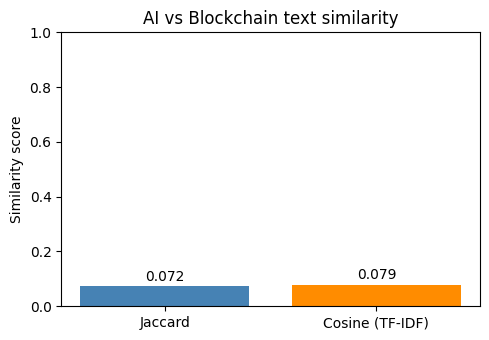

In [21]:
import matplotlib.pyplot as plt

plt.figure(figsize=(5, 3.5))
plt.bar(["Jaccard", "Cosine (TF-IDF)"], [jaccard, cos_sim], color=["steelblue", "darkorange"])
plt.ylim(0, 1); plt.ylabel("Similarity score")
plt.title("AI vs Blockchain text similarity")
for i, v in enumerate([jaccard, cos_sim]):
    plt.text(i, v + 0.02, f"{v:.3f}", ha="center")
plt.tight_layout(); plt.show()

### Q4.2c Which metric gives better insight?

| | Jaccard | Cosine + TF-IDF |
|---|---|---|
| What it measures | overlap of **unique word sets** | angle between **weighted word vectors** |
| Word frequency / importance | ignored (a word counts once) | used – rare, informative words weigh more |
| Text length sensitivity | penalises long vs short texts (large union) | normalised for length |

**Results:** Jaccard ≈ **0.07** and cosine ≈ **0.08**. Both are very low, which is correct: AI and Blockchain are different technologies and the only shared words are generic ones – *technology, data, finance, used, widely*.

**Conclusion:** I prefer **cosine similarity with TF-IDF** for this case, because it uses more information than Jaccard: it counts how often a word occurs (e.g. *data* appears twice in the AI text, so it gets a larger weight) and it is normalised for text length, whereas Jaccard only checks whether a word is present or not. In this particular example the two numbers are close, so the practical difference is small – with only **two** short documents the IDF part of TF-IDF cannot do much (a word is either in both documents or in one). The advantage of cosine/TF-IDF becomes much clearer on larger collections of documents. Jaccard is still useful as a quick, easy-to-explain measure (e.g. comparing keyword/tag sets or detecting near-duplicate short texts).

---
# Q5. Sentiment analysis (TextBlob + VADER) and Word Cloud
**Product:** Wireless earbuds (10 short reviews written by me)

In [22]:
import pandas as pd

reviews = [
    "These earbuds are amazing! The sound quality is excellent and the battery lasts all day.",
    "Absolutely love them. Very comfortable, great bass and the price is totally worth it.",
    "Terrible product. The left earbud stopped working after two days and the support was useless.",
    "Worst purchase ever. Poor sound, constant disconnections and a very cheap build.",
    "The earbuds are okay. They connect to my phone and play music.",
    "Good value for money. Fast delivery, nice design and the noise cancellation works really well.",
    "Battery life is disappointing and the case feels flimsy. I regret buying these.",
    "Fantastic experience! Crystal clear calls, lightweight fit and a stylish charging case.",
    "The package contains the earbuds, a charging cable and a user manual.",
    "Superb sound and comfortable fit. Highly recommended for gym and travel!",
]
df = pd.DataFrame({"review": reviews})
df

,review
0,These earbuds are amazing! The sound quality i...
1,"Absolutely love them. Very comfortable, great ..."
2,Terrible product. The left earbud stopped work...
3,"Worst purchase ever. Poor sound, constant disc..."
4,The earbuds are okay. They connect to my phone...
5,"Good value for money. Fast delivery, nice desi..."
6,Battery life is disappointing and the case fee...
7,"Fantastic experience! Crystal clear calls, lig..."
8,"The package contains the earbuds, a charging c..."
9,Superb sound and comfortable fit. Highly recom...


### Q5.1 Polarity and subjectivity (TextBlob) + VADER compound score

In [23]:
from textblob import TextBlob
from nltk.sentiment.vader import SentimentIntensityAnalyzer

sia = SentimentIntensityAnalyzer()

df["polarity"]     = df["review"].apply(lambda r: TextBlob(r).sentiment.polarity)
df["subjectivity"] = df["review"].apply(lambda r: TextBlob(r).sentiment.subjectivity)
df["vader_compound"] = df["review"].apply(lambda r: sia.polarity_scores(r)["compound"])

pd.set_option("display.max_colwidth", 70)
display(df.round(3))

,review,polarity,subjectivity,vader_compound
0,These earbuds are amazing! The sound quality is excellent and the ...,0.717,0.767,0.831
1,"Absolutely love them. Very comfortable, great bass and the price i...",0.394,0.590,0.940
2,Terrible product. The left earbud stopped working after two days a...,-0.500,0.400,-0.625
3,"Worst purchase ever. Poor sound, constant disconnections and a ver...",-0.096,0.649,-0.802
4,The earbuds are okay. They connect to my phone and play music.,0.500,0.500,0.511
5,"Good value for money. Fast delivery, nice design and the noise can...",0.425,0.600,0.859
6,Battery life is disappointing and the case feels flimsy. I regret ...,-0.600,0.700,-0.718
7,"Fantastic experience! Crystal clear calls, lightweight fit and a s...",0.375,0.671,0.840
8,"The package contains the earbuds, a charging cable and a user manual.",0.000,0.000,0.000
9,Superb sound and comfortable fit. Highly recommended for gym and t...,0.480,0.628,0.906


### Q5.2 Classify reviews as Positive / Negative / Neutral
Rule used on the TextBlob polarity score (range −1 to +1):
* polarity **> 0.1** → Positive  
* polarity **< −0.1** → Negative  
* otherwise → Neutral

In [24]:
def classify(p, pos_th=0.1, neg_th=-0.1):
    if p > pos_th:  return "Positive"
    if p < neg_th:  return "Negative"
    return "Neutral"

df["sentiment (TextBlob)"] = df["polarity"].apply(classify)
df["sentiment (VADER)"]    = df["vader_compound"].apply(lambda c: classify(c, 0.05, -0.05))

display(df[["review", "polarity", "subjectivity", "sentiment (TextBlob)", "sentiment (VADER)"]].round(3))

print("\nTextBlob counts:\n", df["sentiment (TextBlob)"].value_counts())
print("\nVADER counts:\n", df["sentiment (VADER)"].value_counts())

,review,polarity,subjectivity,sentiment (TextBlob),sentiment (VADER)
0,These earbuds are amazing! The sound quality is excellent and the ...,0.717,0.767,Positive,Positive
1,"Absolutely love them. Very comfortable, great bass and the price i...",0.394,0.590,Positive,Positive
2,Terrible product. The left earbud stopped working after two days a...,-0.500,0.400,Negative,Negative
3,"Worst purchase ever. Poor sound, constant disconnections and a ver...",-0.096,0.649,Neutral,Negative
4,The earbuds are okay. They connect to my phone and play music.,0.500,0.500,Positive,Positive
5,"Good value for money. Fast delivery, nice design and the noise can...",0.425,0.600,Positive,Positive
6,Battery life is disappointing and the case feels flimsy. I regret ...,-0.600,0.700,Negative,Negative
7,"Fantastic experience! Crystal clear calls, lightweight fit and a s...",0.375,0.671,Positive,Positive
8,"The package contains the earbuds, a charging cable and a user manual.",0.000,0.000,Neutral,Neutral
9,Superb sound and comfortable fit. Highly recommended for gym and t...,0.480,0.628,Positive,Positive



TextBlob counts:
 sentiment (TextBlob)
Positive    6
Negative    2
Neutral     2
Name: count, dtype: int64

VADER counts:
 sentiment (VADER)
Positive    6
Negative    3
Neutral     1
Name: count, dtype: int64


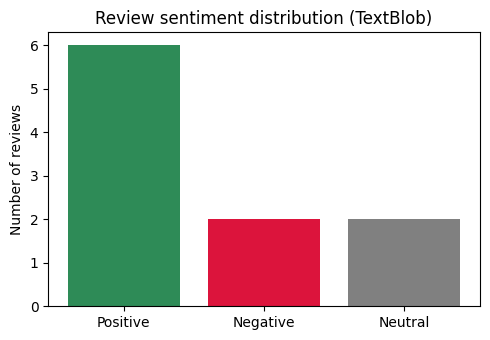

In [25]:
import matplotlib.pyplot as plt

counts = df["sentiment (TextBlob)"].value_counts()
colors = {"Positive": "seagreen", "Negative": "crimson", "Neutral": "gray"}
plt.figure(figsize=(5, 3.5))
plt.bar(counts.index, counts.values, color=[colors[c] for c in counts.index])
plt.title("Review sentiment distribution (TextBlob)")
plt.ylabel("Number of reviews")
plt.tight_layout(); plt.show()

### Q5.3 Word cloud of all positive reviews

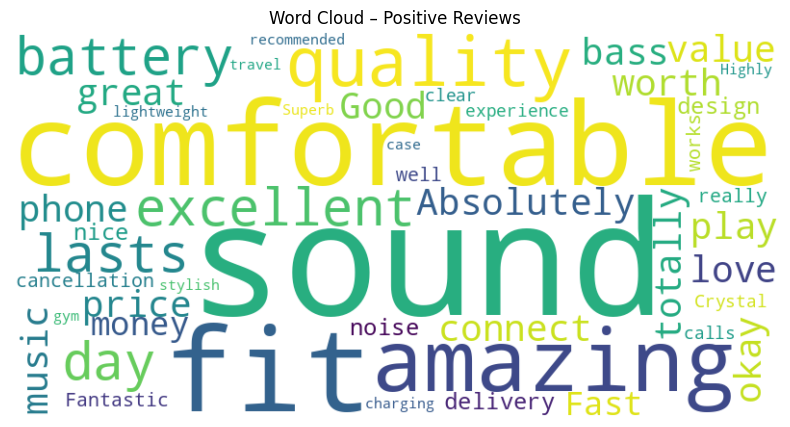

In [26]:
from wordcloud import WordCloud, STOPWORDS
import matplotlib.pyplot as plt

positive_text = " ".join(df.loc[df["sentiment (TextBlob)"] == "Positive", "review"])

wc = WordCloud(width=800, height=400, background_color="white",
               stopwords=STOPWORDS | {"earbuds"}, colormap="viridis").generate(positive_text)

plt.figure(figsize=(10, 5))
plt.imshow(wc, interpolation="bilinear")
plt.axis("off")
plt.title("Word Cloud – Positive Reviews")
plt.show()

**Observation:**
* Reviews with strongly positive words (*amazing, excellent, love, fantastic, superb*) get a high polarity, and *terrible, disappointing, regret* give a negative polarity. The purely factual review about the package contents has polarity 0 and subjectivity 0, so it is Neutral. TextBlob's **subjectivity** is high for opinion-heavy reviews and low for factual ones.
* **The two tools disagree on one review:** "*Worst purchase ever. Poor sound, constant disconnections…*" has a TextBlob polarity of only about −0.10 (so it falls in my Neutral band), while VADER gives about −0.80 (Negative) – the correct label. VADER is designed for short, informal reviews, so it handles strong words like *worst* and punctuation better.
* Both tools label "*The earbuds are okay…*" as Positive because *okay* has a mildly positive score, although a human would probably call it Neutral. This shows the limits of lexicon-based sentiment analysis (no real understanding of context).
* In the word cloud the largest words are *sound, comfortable* and *fit* show what customers like most.

---
# Q6. Text generation with Keras (LSTM)
Training data: a ~100-word paragraph about cricket.

In [27]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"   # hide TensorFlow info messages
os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"
import numpy as np
import tensorflow as tf

try:
    from keras.preprocessing.text import Tokenizer            # older Keras
except ImportError:
    from tensorflow.keras.preprocessing.text import Tokenizer # newer Keras (3.x) keeps it under tf.keras
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Input
from tensorflow.keras.utils import to_categorical

np.random.seed(42)
tf.random.set_seed(42)

training_text = (
    "cricket is a game of passion and patience. every morning the players practice in the ground "
    "and dream of playing for the country. the batter watches the ball carefully and plays a perfect shot. "
    "the bowler runs in fast and the crowd cheers loudly. the fielders dive to save every run. "
    "a captain must stay calm and lead the team in difficult moments. "
    "the match is tense till the last over and every ball can change the game. "
    "the coach shares simple advice and the young players listen with respect. "
    "cricket teaches us teamwork and never giving up."
)
print("Number of words in training text:", len(training_text.split()))

Number of words in training text: 98


### Q6.1 Tokenize with Keras `Tokenizer()`

In [28]:
tokenizer = Tokenizer()
tokenizer.fit_on_texts([training_text])

total_words = len(tokenizer.word_index) + 1     # +1 because index 0 is reserved for padding
print("Vocabulary size:", total_words - 1)
print("First 15 entries of word_index:", dict(list(tokenizer.word_index.items())[:15]))

Vocabulary size: 66
First 15 entries of word_index: {'the': 1, 'and': 2, 'a': 3, 'every': 4, 'in': 5, 'cricket': 6, 'is': 7, 'game': 8, 'of': 9, 'players': 10, 'ball': 11, 'passion': 12, 'patience': 13, 'morning': 14, 'practice': 15}


### Q6.2 Create input sequences and build the model

In [29]:
# Build n-gram sequences from each sentence: [w1,w2], [w1,w2,w3], ...
input_sequences = []
for sentence in training_text.split("."):
    sentence = sentence.strip()
    if not sentence:
        continue
    token_list = tokenizer.texts_to_sequences([sentence])[0]
    for i in range(2, len(token_list) + 1):
        input_sequences.append(token_list[:i])

max_len = max(len(s) for s in input_sequences)
input_sequences = np.array(pad_sequences(input_sequences, maxlen=max_len, padding="pre"))

X = input_sequences[:, :-1]               # all words except the last = input
y = input_sequences[:, -1]                # last word = target
y = to_categorical(y, num_classes=total_words)

print("Number of training sequences:", len(input_sequences))
print("X shape:", X.shape, " y shape:", y.shape)

model = Sequential([
    Input(shape=(max_len - 1,)),
    Embedding(total_words, 64),
    LSTM(100),
    Dense(total_words, activation="softmax"),
])
model.compile(loss="categorical_crossentropy", optimizer="adam", metrics=["accuracy"])
model.summary()

Number of training sequences: 89
X shape: (89, 14)  y shape: (89, 67)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 14, 64)         │         4,288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 100)            │        66,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 67)             │         6,767 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 77,055 (301.00 KB)

 Trainable params: 77,055 (301.00 KB)

 Non-trainable params: 0 (0.00 B)

### Q6.3 Train the model

Final training loss    : 0.1269
Final training accuracy: 0.9326


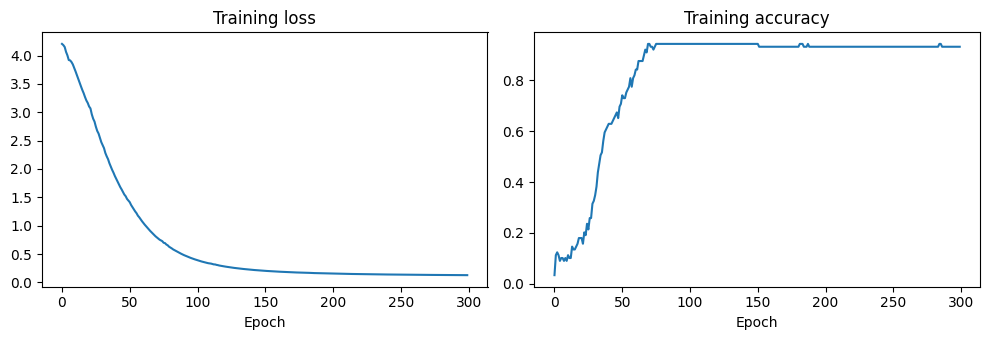

In [30]:
history = model.fit(X, y, epochs=300, batch_size=16, verbose=0)

print(f"Final training loss    : {history.history['loss'][-1]:.4f}")
print(f"Final training accuracy: {history.history['accuracy'][-1]:.4f}")

import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(history.history["loss"]);     ax[0].set_title("Training loss");     ax[0].set_xlabel("Epoch")
ax[1].plot(history.history["accuracy"]); ax[1].set_title("Training accuracy"); ax[1].set_xlabel("Epoch")
plt.tight_layout(); plt.show()

### Q6.4 Generate new lines of text from seed words

In [31]:
index_to_word = {idx: w for w, idx in tokenizer.word_index.items()}

def sample_with_temperature(probs, temperature=0.8):
    probs = np.asarray(probs).astype("float64")
    probs = np.log(probs + 1e-9) / temperature
    probs = np.exp(probs) / np.sum(np.exp(probs))
    return np.random.choice(len(probs), p=probs)

def generate_text(seed_text, next_words=12, temperature=0.8):
    result = seed_text
    for _ in range(next_words):
        token_list = tokenizer.texts_to_sequences([result])[0]
        token_list = pad_sequences([token_list], maxlen=max_len - 1, padding="pre")
        probs = model.predict(token_list, verbose=0)[0]
        next_idx = sample_with_temperature(probs, temperature)
        result += " " + index_to_word.get(next_idx, "")
    return result

for seed in ["cricket", "the batter", "every"]:
    print(f"Seed: '{seed}'")
    print("   ->", generate_text(seed))
    print()

Seed: 'cricket'
   -> cricket is a game of passion and patience up listen with cricket never

Seed: 'the batter'
   -> the batter watches the ball carefully and plays a perfect shot shot dive plays

Seed: 'every'
   -> every morning the players practice in the ground and dream of playing for



**Observation:** The training text is very small (~100 words), so the model mostly memorises phrases from it and the generated lines look like re-mixed versions of the original paragraph. Some lines get stuck repeating a word (e.g. *shot shot*) and are only loosely grammatical. Because the words are sampled randomly, your own output will differ from run to run. Using a much larger corpus, more LSTM layers/units, and more epochs would give more varied and meaningful text. The `temperature` parameter controls randomness: low values → safer, repetitive text; high values → more creative but less coherent.

---